In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler
# Display settings — make wide tables readable
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Plot styling — pick one and stick with it for a consistent deck
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Reproducibility — any random sampling we do should be the same on every run
RNG = np.random.default_rng(42)

In [3]:
df = pd.read_csv('financial_risk_assessment.csv')
df.head()

,Age,Gender,Education Level,Marital Status,Income,Credit Score,Loan Amount,Loan Purpose,Employment Status,Years at Current Job,Payment History,Debt-to-Income Ratio,Assets Value,Number of Dependents,City,State,Country,Previous Defaults,Marital Status Change,Risk Rating
0,49,Male,PhD,Divorced,"72,799.0000",688.0000,"45,713.0000",Business,Unemployed,19,Poor,0.1543,"120,228.0000",0.0000,Port Elizabeth,AS,Cyprus,2.0000,2,Low
1,57,Female,Bachelor's,Widowed,NaN,690.0000,"33,835.0000",Auto,Employed,6,Fair,0.1489,"55,849.0000",0.0000,North Catherine,OH,Turkmenistan,3.0000,2,Medium
2,21,Non-binary,Master's,Single,"55,687.0000",600.0000,"36,623.0000",Home,Employed,8,Fair,0.3624,"180,700.0000",3.0000,South Scott,OK,Luxembourg,3.0000,2,Medium
3,59,Male,Bachelor's,Single,"26,508.0000",622.0000,"26,541.0000",Personal,Unemployed,2,Excellent,0.4550,"157,319.0000",3.0000,Robinhaven,PR,Uganda,4.0000,2,Medium
4,25,Non-binary,Bachelor's,Widowed,"49,427.0000",766.0000,"36,528.0000",Personal,Unemployed,10,Fair,0.1432,"287,140.0000",NaN,New Heather,IL,Namibia,3.0000,1,Low


In [5]:
# Shape and dtypes
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print()
print("Dtype counts:")
print(df.dtypes.value_counts())

Rows: 15,000
Columns: 20

Dtype counts:
str        10
float64     7
int64       3
Name: count, dtype: int64


In [14]:
risk_rating_summary = pd.DataFrame({
    "count": df["Risk Rating"].value_counts(),
    "percentage": (df["Risk Rating"].value_counts(normalize=True) * 100).round(2)
})

risk_rating_summary

,count,percentage
Risk Rating,,
Low,9000,60.0000
Medium,4500,30.0000
High,1500,10.0000


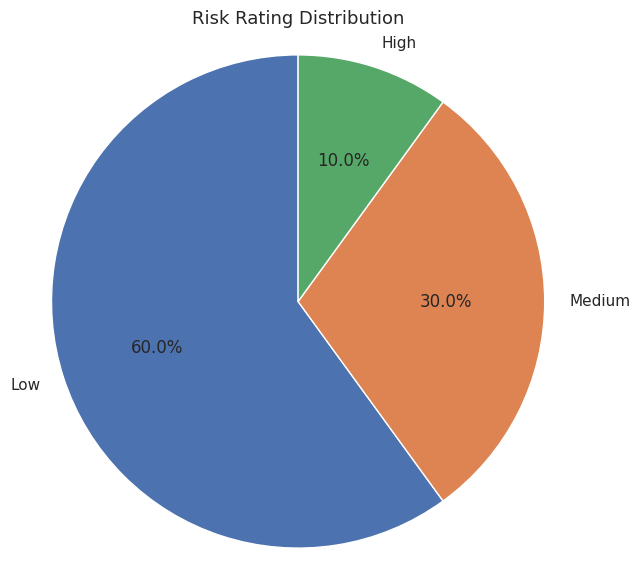

In [53]:
plt.figure(figsize=(7, 7))
plt.pie(
    risk_rating_summary["count"],
    labels=risk_rating_summary.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Risk Rating Distribution")
plt.axis('equal')

plt.show()

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    15000 non-null  int64  
 1   Gender                 15000 non-null  str    
 2   Education Level        15000 non-null  str    
 3   Marital Status         15000 non-null  str    
 4   Income                 12750 non-null  float64
 5   Credit Score           12750 non-null  float64
 6   Loan Amount            12750 non-null  float64
 7   Loan Purpose           15000 non-null  str    
 8   Employment Status      15000 non-null  str    
 9   Years at Current Job   15000 non-null  int64  
 10  Payment History        15000 non-null  str    
 11  Debt-to-Income Ratio   15000 non-null  float64
 12  Assets Value           12750 non-null  float64
 13  Number of Dependents   12750 non-null  float64
 14  City                   15000 non-null  str    
 15  State        

In [8]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
numeric_df = pd.DataFrame({
    "Numeric_Columns": numeric_cols
})
print(numeric_df)
print(f"\nTotal numeric columns: {len(numeric_cols)}")

         Numeric_Columns
0                    Age
1                 Income
2           Credit Score
3            Loan Amount
4   Years at Current Job
5   Debt-to-Income Ratio
6           Assets Value
7   Number of Dependents
8      Previous Defaults
9  Marital Status Change

Total numeric columns: 10


In [10]:
categorical_cols = df.select_dtypes(include=["object", "category","str"]).columns.tolist()
categorical_df = pd.DataFrame({
    "Categorical_Columns": categorical_cols
})
print(categorical_df)
print(f"\nTotal categorical columns: {len(categorical_cols)}")

  Categorical_Columns
0              Gender
1     Education Level
2      Marital Status
3        Loan Purpose
4   Employment Status
5     Payment History
6                City
7               State
8             Country
9         Risk Rating

Total categorical columns: 10


In [4]:
for col in df.columns:
    print("==================")
    print(f"{col}\n{df[col].unique()}\nNumber of unique values: {df[col].nunique()}")
    print("==================\n")

Age
[49 57 21 59 25 30 31 18 32 55 42 37 60 68 29 56 26 22 64 41 36 34 48 69
 46 47 35 67 28 65 39 27 54 19 44 20 62 66 50 38 24 23 40 45 43 58 52 33
 53 63 51 61]
Number of unique values: 52

Gender
<StringArray>
['Male', 'Female', 'Non-binary']
Length: 3, dtype: str
Number of unique values: 3

Education Level
<StringArray>
['PhD', 'Bachelor's', 'Master's', 'High School']
Length: 4, dtype: str
Number of unique values: 4

Marital Status
<StringArray>
['Divorced', 'Widowed', 'Single', 'Married']
Length: 4, dtype: str
Number of unique values: 4

Income
[ 72799.     nan  55687. ...  48088. 107193.  40180.]
Number of unique values: 11957

Credit Score
[688. 690. 600. 622. 766. 717. 672.  nan 710. 707. 718. 686. 706. 654.
 738. 702. 796. 664. 641. 742. 667. 791. 749. 636. 632. 673. 637. 685.
 604. 606. 783. 715. 748. 631. 691. 703. 763. 721. 613. 727. 764. 608.
 635. 612. 720. 712. 647. 649. 750. 650. 700. 692. 793. 726. 615. 708.
 627. 680. 670. 792. 640. 734. 617. 663. 770. 740. 645. 687.

In [83]:
country_state_check = (
    df.groupby("Country")["State"]
    .nunique()
    .sort_values(ascending=False)
)

with pd.option_context('display.max_rows', None):
    display(country_state_check)

Country
Congo                                                  51
Korea                                                  49
France                                                 48
French Guiana                                          48
Holy See (Vatican City State)                          46
Turkey                                                 45
Taiwan                                                 45
Swaziland                                              45
Nauru                                                  45
Puerto Rico                                            45
Pakistan                                               45
South Africa                                           45
Namibia                                                44
Bosnia and Herzegovina                                 44
Eritrea                                                44
British Indian Ocean Territory (Chagos Archipelago)    44
Cape Verde                                             44
Centra

In [85]:
df[df["Country"] == "United States of America"]

,Age,Gender,Education Level,Marital Status,Income,Credit Score,Loan Amount,Loan Purpose,Employment Status,Years at Current Job,Payment History,Debt-to-Income Ratio,Assets Value,Number of Dependents,City,State,Country,Previous Defaults,Marital Status Change,Risk Rating
333,28,Male,Bachelor's,Single,"83,969.0000",671.0000,"44,332.0000",Business,Employed,16,Fair,0.4570,"88,597.0000",0.0000,Julieborough,FM,United States of America,2.0000,2,Low
937,58,Female,High School,Married,"47,431.0000",764.0000,NaN,Auto,Unemployed,15,Good,0.2935,NaN,1.0000,Lake Derekport,GU,United States of America,3.0000,0,Low
993,49,Male,High School,Divorced,NaN,789.0000,"26,720.0000",Home,Self-employed,7,Excellent,0.1804,"56,472.0000",1.0000,East Jennifer,CA,United States of America,3.0000,1,Low
1031,57,Female,PhD,Divorced,"52,174.0000",740.0000,"43,639.0000",Personal,Self-employed,19,Fair,0.2476,"295,230.0000",4.0000,West Rachel,IN,United States of America,0.0000,2,Medium
1337,62,Male,PhD,Widowed,"25,888.0000",780.0000,NaN,Personal,Employed,4,Poor,0.3525,"213,368.0000",1.0000,Mariaberg,UT,United States of America,1.0000,0,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14105,49,Non-binary,PhD,Married,"76,889.0000",762.0000,"47,660.0000",Home,Employed,2,Excellent,0.1392,"197,757.0000",NaN,East Alexander,MO,United States of America,0.0000,1,High
14156,20,Female,Master's,Divorced,"70,547.0000",712.0000,"13,567.0000",Auto,Unemployed,4,Fair,0.3517,"258,055.0000",4.0000,Steinhaven,AK,United States of America,3.0000,0,Low
14169,23,Female,High School,Single,"117,681.0000",762.0000,"49,015.0000",Auto,Employed,19,Good,0.1520,"56,005.0000",1.0000,Amandaside,VA,United States of America,0.0000,1,High
14327,60,Male,High School,Single,"27,925.0000",648.0000,"45,221.0000",Personal,Unemployed,10,Excellent,0.3985,"159,979.0000",0.0000,Lake Brentburgh,HI,United States of America,2.0000,1,Low


In [95]:
city_counts = (
    df.groupby(["State", "City"], dropna=False)
    .size()
    .reset_index(name="row_count")
    .sort_values("row_count", ascending=False)
)
city_counts.head(10)

,State,City,row_count
8886,NH,East Steven,3
6742,MI,South Jennifer,3
13354,VA,Wilsonview,2
623,AR,New Dawn,2
4365,IL,Josephbury,2
14709,WY,Markside,2
5456,LA,Port Kevin,2
3365,GU,Johnchester,2
8547,ND,Taylorbury,2
862,AS,Lake Jacob,2


In [88]:
city_count_summary = city_counts["row_count"].describe()

print(city_count_summary)

print("\nNumber of cities with only 1 row:", (city_counts["row_count"] == 1).sum())
print("Number of cities with at least 5 rows:", (city_counts["row_count"] >= 5).sum())
print("Number of cities with at least 10 rows:", (city_counts["row_count"] >= 10).sum())

count   14,858.0000
mean         1.0096
std          0.0987
min          1.0000
25%          1.0000
50%          1.0000
75%          1.0000
max          3.0000
Name: row_count, dtype: float64

Number of cities with only 1 row: 14718
Number of cities with at least 5 rows: 0
Number of cities with at least 10 rows: 0


In [96]:
city_income = (
    df.groupby(["State", "City"], dropna=False)["Income"]
    .agg(
        city_count="size",
        income_count="count",
        city_mean_income="mean",
        city_median_income="median"
    )
    .reset_index()
)
min_city_income_count = 5

city_income_filtered = city_income[
    city_income["income_count"] >= min_city_income_count
].copy()

print("Cities before filtering:", city_income.shape[0])
print("Cities after filtering:", city_income_filtered.shape[0])

Cities before filtering: 14858
Cities after filtering: 0


In [ ]:
ordinal_maps = {
    "Education Level": {
        "High School": 1,
        "Bachelor's": 2,
        "Master's": 3,
        "PhD": 4
    },

    "Payment History": {
        "Poor": 1,
        "Fair": 2,
        "Good": 3,
        "Excellent": 4
    },

    "Risk Rating": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    }
}

In [ ]:
def encode_ordinal_features(df, encoding_dict):
    for col, mapping in encoding_dict.items():
        df[col] = df[col].map(mapping).astype("Int64")
    return df

In [ ]:
df_fixed = df.copy()

In [ ]:
df_fixed["Marital Status Change"] = df_fixed["Marital Status Change"].astype("category")

In [ ]:
nominal_categorical_cols = [
    "Gender",
    "Marital Status",
    "Loan Purpose",
    "Employment Status",
    "City",
    "State",
    "Country"
]

for col in nominal_categorical_cols:
    df_fixed[col] = df_fixed[col].astype("category")

In [ ]:
df_fixed = encode_ordinal_features(df_fixed, ordinal_maps)

In [ ]:
df_fixed.drop(columns=["City"], inplace=True)

### Numerical codes that are actually categories

`Marital Status Change` is stored as a numeric column, but it should not be treated as a normal continuous number. The column only has the values `0`, `1`, and `2`, which means these values are most likely codes for different categories. The problem is that the dataset does not clearly explain what each code means. Because of that, I should not assume that `2` is greater, better, or twice as much as `1`. For EDA, I would treat it as a categorical feature and check how each code is related to `Risk Rating`. For modeling, it should be encoded as a category unless the real meaning of the codes is explained.

### Ordinal categorical features

Some columns are categorical, but their values have a clear order. In this dataset, these columns are `Education Level`, `Payment History`, and `Risk Rating`.

`Education Level` has the values `High School`, `Bachelor's`, `Master's`, and `PhD`. These categories have a natural order from lower to higher education level. Because of this, it can be encoded in order instead of treating the values as completely unrelated categories.

`Payment History` also has a clear order: `Poor`, `Fair`, `Good`, and `Excellent`. This is important because payment history is likely connected to financial risk. A person with `Excellent` payment history should not be treated the same way as a person with `Poor` payment history.

### Target feature

`Risk Rating` is the target variable and it also has an order: `Low`, `Medium`, and `High`. The target is imbalanced, with 9,000 Low-risk clients, 4,500 Medium-risk clients, and 1,500 High-risk clients. This means 60% of the dataset is Low risk and only 10% is High risk, so later analysis should be careful not to ignore the smaller High-risk group. Because of this imbalance, accuracy alone would not be enough if this dataset is later used for modeling. A model could mostly predict `Low` risk and still look good overall, while performing badly on the `High` risk group.

### Count-like numeric features

Some numeric columns are not normal continuous measurements. They are counts. These include `Years at Current Job`, `Number of Dependents`, and `Previous Defaults`.

`Years at Current Job` counts how many years a person has worked at the current job. `Number of Dependents` counts how many people depend on that person financially. `Previous Defaults` counts how many previous defaults the person had. These columns should not be interpreted the same way as `Income` or `Loan Amount`, because they take a small number of repeated values.

### Column names that were unclear

#### `Marital Status Change`

`Marital Status Change` is unclear because it contains the numeric values `0`, `1`, and `2`, but the column name does not explain what each number means. This matters because it looks numeric, but it is probably a coded category. If I treat it like a normal number, the model may learn a false relationship.

#### `Previous Defaults`

`Previous Defaults` is also partly unclear. The general idea is understandable: it probably means how many times the person failed to repay a previous loan or debt. For example, a value of `0` could mean no previous defaults, while a value of `3` could mean the person defaulted three times before. The unclear part is the exact definition. The dataset does not explain whether this column counts only loan defaults, credit card defaults, all financial defaults, or defaults during a specific time period. This matters because `Previous Defaults` is likely connected to `Risk Rating`, but missing values should not automatically be treated as `0`. A missing value may mean unknown history, but not no previous defaults.

### Location columns issue

The location columns need special attention. I assume that `Country` represents the individual’s country of origin, but `City` and `State` do not look reliable enough for strong geographic analysis. I checked whether `City` might still be useful by looking at how many rows each city has. The result shows that there are **14,858 unique State-City combinations**, and almost all of them appear only once. There are **14,718 cities with only 1 row** and there are **0 cities with at least 5 rows**.

Because of this, I cannot reliably compare average income between cities inside the same state. A city with only one person does not give a real city-level average. The result does not prove that income is similar across cities; instead, it shows that the dataset is too sparse at the city level to make that comparison. From a domain point of view, dropping `City` is a good decision for later modeling. `City` has too many unique values and almost no repeated observations, so it would probably add noise instead of useful information. One-hot encoding `City` would create thousands of columns, and most of those columns would represent only one row.

I also found that there are rows where `Country` is `United  States of America`, so the dataset does contain U.S. individuals. However, there are only **64 rows** with `Country = United  States of America` out of **15,000 rows**. This is a small number, especially because many `State` values look like U.S. states or territories. That makes the location fields even less consistent.

### Potential mistake

A common mistake would be to select all numeric columns and use them directly in analysis or modeling. This would incorrectly treat `Marital Status Change` as a normal number, even though it is probably a coded category. It would also treat `Number of Dependents` and `Previous Defaults` like continuous measurements, even though they are count variables.

Another mistake would be to one-hot encode all categorical columns without checking how many unique values they have. This would be especially bad for `City`, because it has more than 10,000 unique values. A third mistake would be to ignore the imbalance in `Risk Rating`, because a model could perform well on the majority `Low` class while doing poorly on the smaller `High` risk class.

In [55]:
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
})

missing = missing[missing["n_missing"] > 0].sort_values("pct_missing", ascending=False)

missing

,n_missing,pct_missing,dtype
Income,2250,15.0000,float64
Credit Score,2250,15.0000,float64
Loan Amount,2250,15.0000,float64
Assets Value,2250,15.0000,float64
Number of Dependents,2250,15.0000,float64
Previous Defaults,2250,15.0000,float64


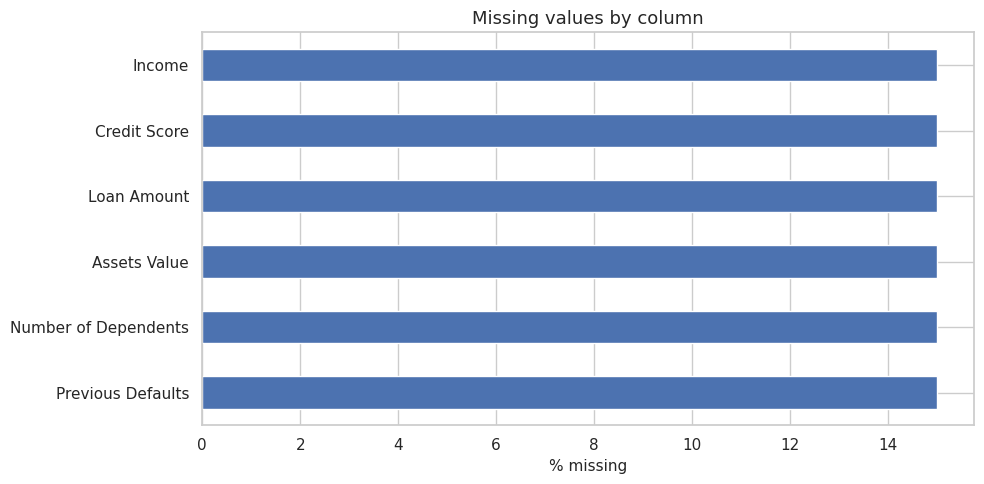

In [56]:
fig, ax = plt.subplots(figsize=(10, 5))
missing["pct_missing"].plot(kind="barh", ax=ax)
ax.set_xlabel("% missing")
ax.set_title("Missing values by column")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [100]:
missing_cols = df.columns[df.isna().any()].tolist()
print("Columns with missing values:")
print(missing_cols)
print("\nNumber of columns with missing values:", len(missing_cols))

Columns with missing values:
['Income', 'Credit Score', 'Loan Amount', 'Assets Value', 'Number of Dependents', 'Previous Defaults']

Number of columns with missing values: 6


In [61]:
missing_na = df[missing_cols].isna()
print(missing_na.any(axis=1).sum(), "rows have at least one missing value in the missing-value columns")
print(missing_na.all(axis=1).sum(), "rows have ALL missing-value columns missing")
print((missing_na.any(axis=1) & ~missing_na.all(axis=1)).sum(), "rows have only SOME missing-value columns missing")

9284 rows have at least one missing value in the missing-value columns
0 rows have ALL missing-value columns missing
9284 rows have only SOME missing-value columns missing


In [64]:
missing_pattern_summary = (
    df[missing_cols]
    .isna()
    .astype(int)
    .groupby(missing_cols)
    .size()
    .reset_index(name="row_count")
    .sort_values("row_count", ascending=False)
)
with pd.option_context('display.max_rows', None):
    display(missing_pattern_summary)

,Income,Credit Score,Loan Amount,Assets Value,Number of Dependents,Previous Defaults,row_count
0,0,0,0,0,0,0,5716
32,1,0,0,0,0,0,1019
1,0,0,0,0,0,1,1004
4,0,0,0,1,0,0,995
16,0,1,0,0,0,0,977
2,0,0,0,0,1,0,960
8,0,0,1,0,0,0,956
24,0,1,1,0,0,0,191
5,0,0,0,1,0,1,190
18,0,1,0,0,1,0,188


In [68]:
missing_by_risk = (
    df.assign(any_missing=df[missing_cols].isna().any(axis=1))
    .groupby("Risk Rating")["any_missing"]
    .agg(count="size", missing_count="sum")
)
missing_by_risk["missing_percent"] = (
    missing_by_risk["missing_count"] / missing_by_risk["count"] * 100
)
missing_by_risk

,count,missing_count,missing_percent
Risk Rating,,,
High,1500,937,62.4667
Low,9000,5576,61.9556
Medium,4500,2771,61.5778


In [70]:
missing_col_by_risk = df.groupby("Risk Rating")[missing_cols].apply(
    lambda group: group.isna().mean() * 100
)
missing_col_by_risk

,Income,Credit Score,Loan Amount,Assets Value,Number of Dependents,Previous Defaults
Risk Rating,,,,,,
High,16.0000,14.4000,15.5333,16.0000,15.4000,13.7333
Low,14.8111,14.8778,15.1889,15.2111,14.8889,14.7444
Medium,15.0444,15.4444,14.4444,14.2444,15.0889,15.9333


In [82]:
for col in ["Number of Dependents", "Previous Defaults"]:
    print(df[col].value_counts(dropna=False).sort_index())
    print("\n")

Number of Dependents
0.0000    2443
1.0000    2590
2.0000    2516
3.0000    2588
4.0000    2613
NaN       2250
Name: count, dtype: int64


Previous Defaults
0.0000    2571
1.0000    2569
2.0000    2559
3.0000    2487
4.0000    2564
NaN       2250
Name: count, dtype: int64




In [116]:
missing_cols = df.columns[df.isna().any()].tolist()
missing_distribution_summary = pd.DataFrame({
    "missing_count": df[missing_cols].isna().sum(),
    "missing_percent": (df[missing_cols].isna().mean() * 100).round(2),
    "mean": df[missing_cols].mean(),
    "median": df[missing_cols].median(),
    "std": df[missing_cols].std(),
    "min": df[missing_cols].min(),
    "max": df[missing_cols].max(),
    "unique_values": df[missing_cols].nunique(dropna=True)
})

missing_distribution_summary

,missing_count,missing_percent,mean,median,std,min,max,unique_values
Income,2250,15.0000,"69,933.3985","69,773.0000","29,163.6262","20,005.0000","119,997.0000",11957
Credit Score,2250,15.0000,699.1091,699.0000,57.2295,600.0000,799.0000,200
Loan Amount,2250,15.0000,"27,450.0109","27,544.0000","12,949.9401","5,000.0000","49,998.0000",11088
Assets Value,2250,15.0000,"159,741.4972","159,362.0000","80,298.1158","20,055.0000","299,999.0000",12470
Number of Dependents,2250,15.0000,2.0265,2.0000,1.4113,0.0000,4.0000,5
Previous Defaults,2250,15.0000,1.9925,2.0000,1.4169,0.0000,4.0000,5


In [117]:
count_missing_cols = ["Number of Dependents", "Previous Defaults"]

count_mode_summary = pd.DataFrame({
    "mode": [df[col].mode(dropna=True).iloc[0] for col in count_missing_cols],
    "median": [df[col].median() for col in count_missing_cols],
    "mean": [df[col].mean() for col in count_missing_cols],
    "missing_count": [df[col].isna().sum() for col in count_missing_cols],
    "unique_values": [df[col].nunique(dropna=True) for col in count_missing_cols]
}, index=count_missing_cols)

count_mode_summary

,mode,median,mean,missing_count,unique_values
Number of Dependents,4.0000,2.0000,2.0265,2250,5
Previous Defaults,0.0000,2.0000,1.9925,2250,5


In [104]:
continuous_missing_cols = [
    "Income",
    "Credit Score",
    "Loan Amount",
    "Assets Value"
]

count_missing_cols = [
    "Number of Dependents",
    "Previous Defaults"
]

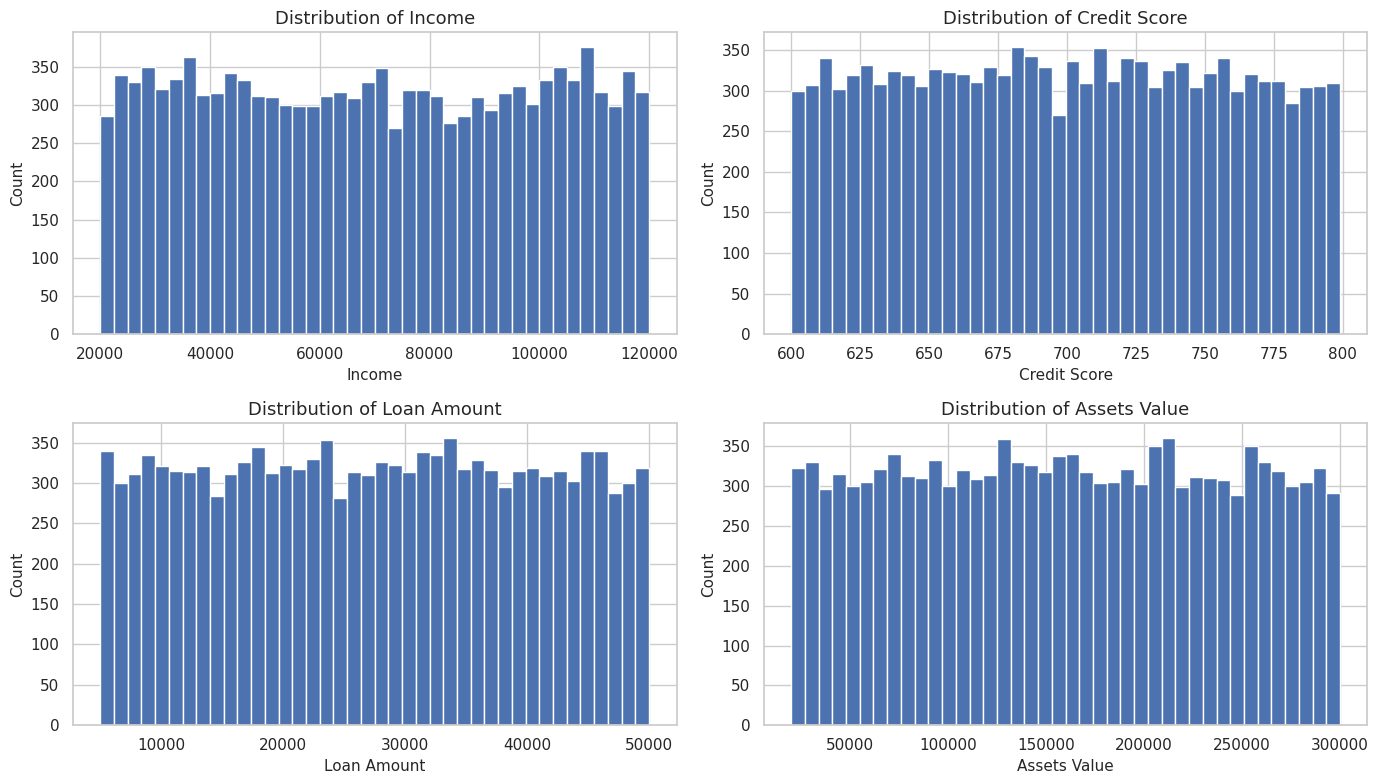

In [105]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(continuous_missing_cols):
    axes[i].hist(df[col].dropna(), bins=40)
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

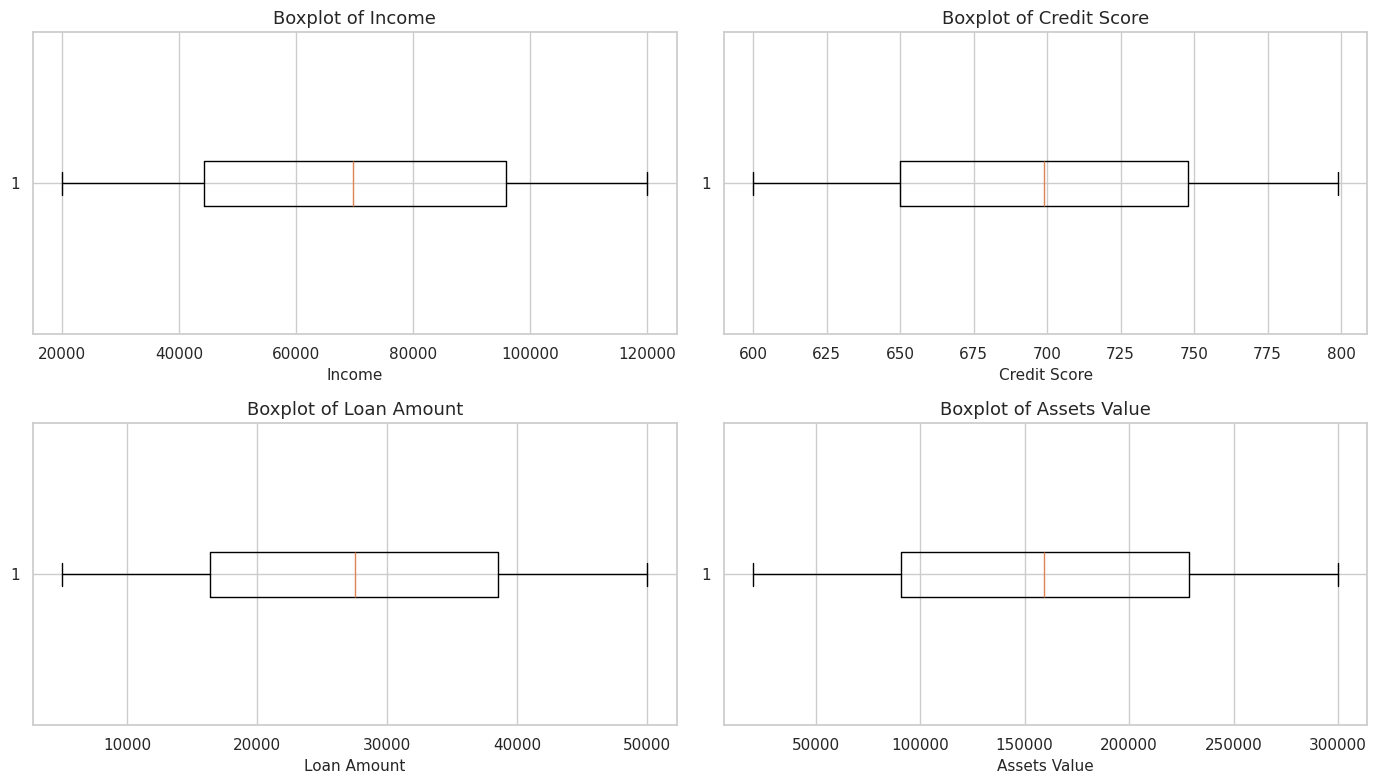

In [106]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(continuous_missing_cols):
    axes[i].boxplot(df[col].dropna(), vert=False)
    axes[i].set_title(f"Boxplot of {col}")
    axes[i].set_xlabel(col)
    axes[i].ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

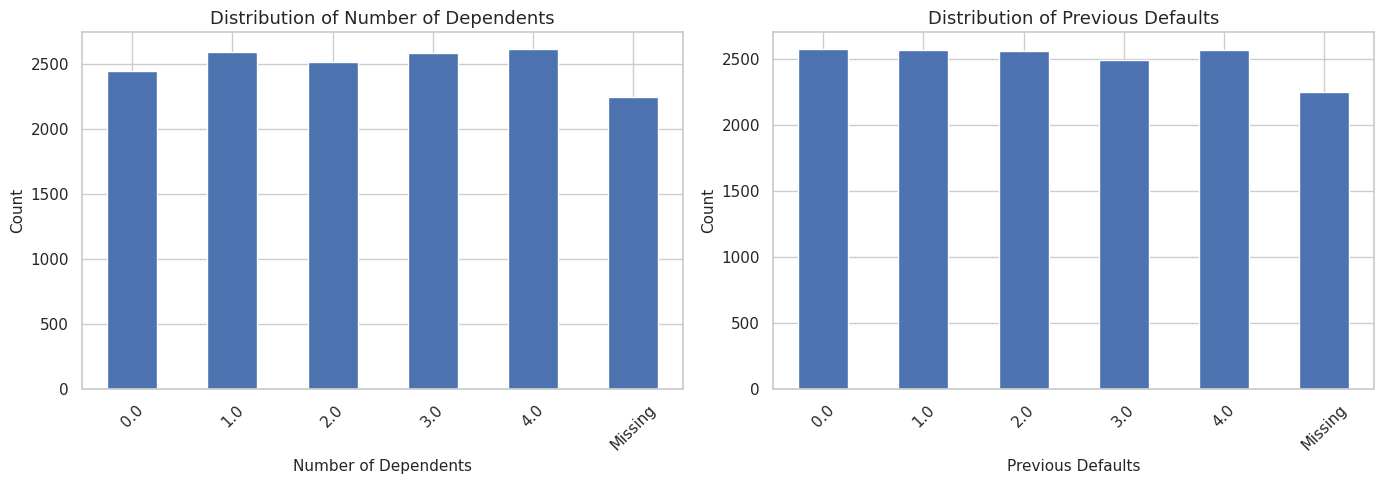

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, col in enumerate(count_missing_cols):
    counts = df[col].astype("string").fillna("Missing").value_counts().sort_index()
    counts.plot(kind="bar", ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [110]:
risk_group_medians = (
    df.groupby("Risk Rating")[continuous_missing_cols]
    .median()
)
risk_group_medians

,Income,Credit Score,Loan Amount,Assets Value
Risk Rating,,,,
High,"66,662.5000",698.5000,"28,129.0000","160,753.5000"
Low,"69,336.0000",700.0000,"27,362.0000","159,513.0000"
Medium,"71,586.0000",699.0000,"27,609.5000","158,141.0000"


In [111]:
employment_group_medians = (
    df.groupby("Employment Status")[continuous_missing_cols]
    .median()
)
employment_group_medians

,Income,Credit Score,Loan Amount,Assets Value
Employment Status,,,,
Employed,"68,702.0000",700.0000,"27,134.5000","160,851.0000"
Self-employed,"71,205.0000",698.0000,"27,884.0000","158,828.0000"
Unemployed,"69,644.0000",700.0000,"27,543.0000","157,868.0000"


In [112]:
education_group_medians = (
    df.groupby("Education Level")[continuous_missing_cols]
    .median()
)
education_group_medians

,Income,Credit Score,Loan Amount,Assets Value
Education Level,,,,
Bachelor's,"69,240.0000",698.0000,"27,093.0000","154,509.0000"
High School,"69,777.0000",697.0000,"27,515.0000","159,661.0000"
Master's,"69,695.0000",698.0000,"27,715.0000","161,208.5000"
PhD,"70,581.0000",704.0000,"27,864.0000","162,307.0000"


In [115]:
count_by_risk = {}

for col in count_missing_cols:
    count_by_risk[col] = pd.crosstab(
        df["Risk Rating"],
        df[col],
        normalize="index"
    )

count_by_risk["Number of Dependents"]

Number of Dependents,0.0000,1.0000,2.0000,3.0000,4.0000
Risk Rating,,,,,
High,0.1939,0.2175,0.1891,0.1946,0.2049
Low,0.1936,0.2013,0.1987,0.2038,0.2026
Medium,0.1869,0.2020,0.1973,0.2041,0.2096


In [114]:
count_by_risk["Previous Defaults"]

Previous Defaults,0.0000,1.0000,2.0000,3.0000,4.0000
Risk Rating,,,,,
High,0.1890,0.2200,0.2020,0.2000,0.1890
Low,0.2090,0.1950,0.2000,0.1930,0.2040
Medium,0.1910,0.2090,0.2020,0.1970,0.2000


### Missing values conclusion

The dataset has missing values in 6 columns: `Income`, `Credit Score`, `Loan Amount`, `Assets Value`, `Number of Dependents`, and `Previous Defaults`. Each of these columns has **2,250 missing values**, which means each one is missing in **15%** of the dataset.

There are **9,284 rows** with at least one missing value, but there are **0 rows** where all 6 missing-value columns are missing at the same time. This means the missing values are not structurally linked in one simple group. In other words, this is not a case where one whole block of information is missing together.

There are **5,716 rows** with no missing values in these columns. The rest of the rows have only some missing values. The most common missingness patterns are single-column missing cases, such as only `Income` missing, only `Previous Defaults` missing, only `Assets Value` missing, only `Credit Score` missing, only `Number of Dependents` missing, or only `Loan Amount` missing. Because of this, I should not use one simple rule for all missing values without checking the meaning of each column.

The missingness also looks similar across the target classes. Around **62%** of rows in each `Risk Rating` group have at least one missing value. More specifically, `High` risk has **62.47%**, `Low` risk has **61.96%**, and `Medium` risk has **61.58%** rows with missing values. This suggests that missingness is not clearly concentrated in only one risk group.

### Are the missing values structural?

The missing values do not look structural. They do not mean that something does not exist.

For example, missing `Income` does not mean the person has no income. Missing `Credit Score` does not mean the person has a credit score of `0`. Missing `Loan Amount` does not mean the person has no loan amount. Missing `Previous Defaults` also should not automatically mean the person has no previous defaults.

Because of that, these missing values should be treated as unknown or not recorded information. Dropping all rows with missing values would remove **9,284 rows**, which is more than half of the dataset, so dropping rows is not a good option here. It is better to keep the rows and impute the missing values carefully.

### Distribution check before imputation

I checked the distributions of the continuous missing-value columns before choosing the imputation method.

The mean and median are very close for these columns, and the histograms look fairly even. The boxplots also do not show strong visible outliers. Because of this, mean imputation would not be terrible, but median imputation is still the safer choice because it is more robust and works well even if some extreme values appear later.

I also checked group medians by `Risk Rating`, `Employment Status`, and `Education Level`. The group medians are not very different from each other. Because of that, group-wise median imputation is possible, but it is not necessary at this point. A simple median imputation is enough and easier to explain.

For the count-like columns, `Number of Dependents` and `Previous Defaults`, the values are spread almost evenly across `0`, `1`, `2`, `3`, and `4`. The median for both columns is `2`. Since the distributions are almost balanced, we can use median or mode.

### Column-by-column imputation decision

| Column | Missing value meaning | Imputation technique | Why |
|---|---|---|---|
| `Income` | Unknown or not recorded income | Fill with median | The distribution is fairly even, the mean and median are close, and median is safer than mean if there are unusual values. |
| `Credit Score` | Unknown or unavailable credit score | Fill with median and consider a missing indicator | The mean and median are almost the same, but a missing credit score may itself carry useful information. It should not be filled with `0`. |
| `Loan Amount` | Unknown or not recorded loan amount | Fill with median | The distribution does not show strong visible outliers, but median is still a safe and simple choice. |
| `Assets Value` | Unknown or not recorded asset value | Fill with median | The mean and median are close, and the boxplot does not show strong outliers. Median keeps the imputation robust. |
| `Number of Dependents` | Unknown number of dependents | Fill with median value `2` | The values from `0` to `4` are almost evenly distributed, so mode is not very meaningful. Missing does not mean `0` dependents. |
| `Previous Defaults` | Unknown previous default history | Fill with median value `2` | The values from `0` to `4` are almost evenly distributed. Missing does not mean the person never defaulted before. |

### Final decision

The missing values should not be filled with `"None"` because these are not categorical “not applicable” fields. They also should not be filled with `0`, because a missing value here does not mean absence. For example, missing `Income` does not mean income is `0`, and missing `Previous Defaults` does not mean the person has no previous defaults.

For the continuous financial columns, I would use **median imputation**: `Income`, `Credit Score`, `Loan Amount`, and `Assets Value`. The distributions are fairly even, the mean and median are close, and there are no strong visible outliers in the boxplots. Median is still a safer default than mean.

For the count-like columns, I would also use the **median value**, which is `2` for both `Number of Dependents` and `Previous Defaults`. After imputation, these columns can be treated as integer-like count features.

I would also consider adding missing-indicator columns, especially for `Credit Score`, `Income`, and `Previous Defaults`, because missing financial information may itself be useful for predicting `Risk Rating`.

In [131]:
cols=["Income","Credit Score","Loan Amount","Assets Value"]
numeric_missing_cols = df[cols].columns.tolist()

skewness_summary = pd.DataFrame({
    "skewness": df[numeric_missing_cols].skew(),
})

skewness_summary

,skewness
Income,0.0104
Credit Score,0.0064
Loan Amount,-0.0014
Assets Value,0.0016


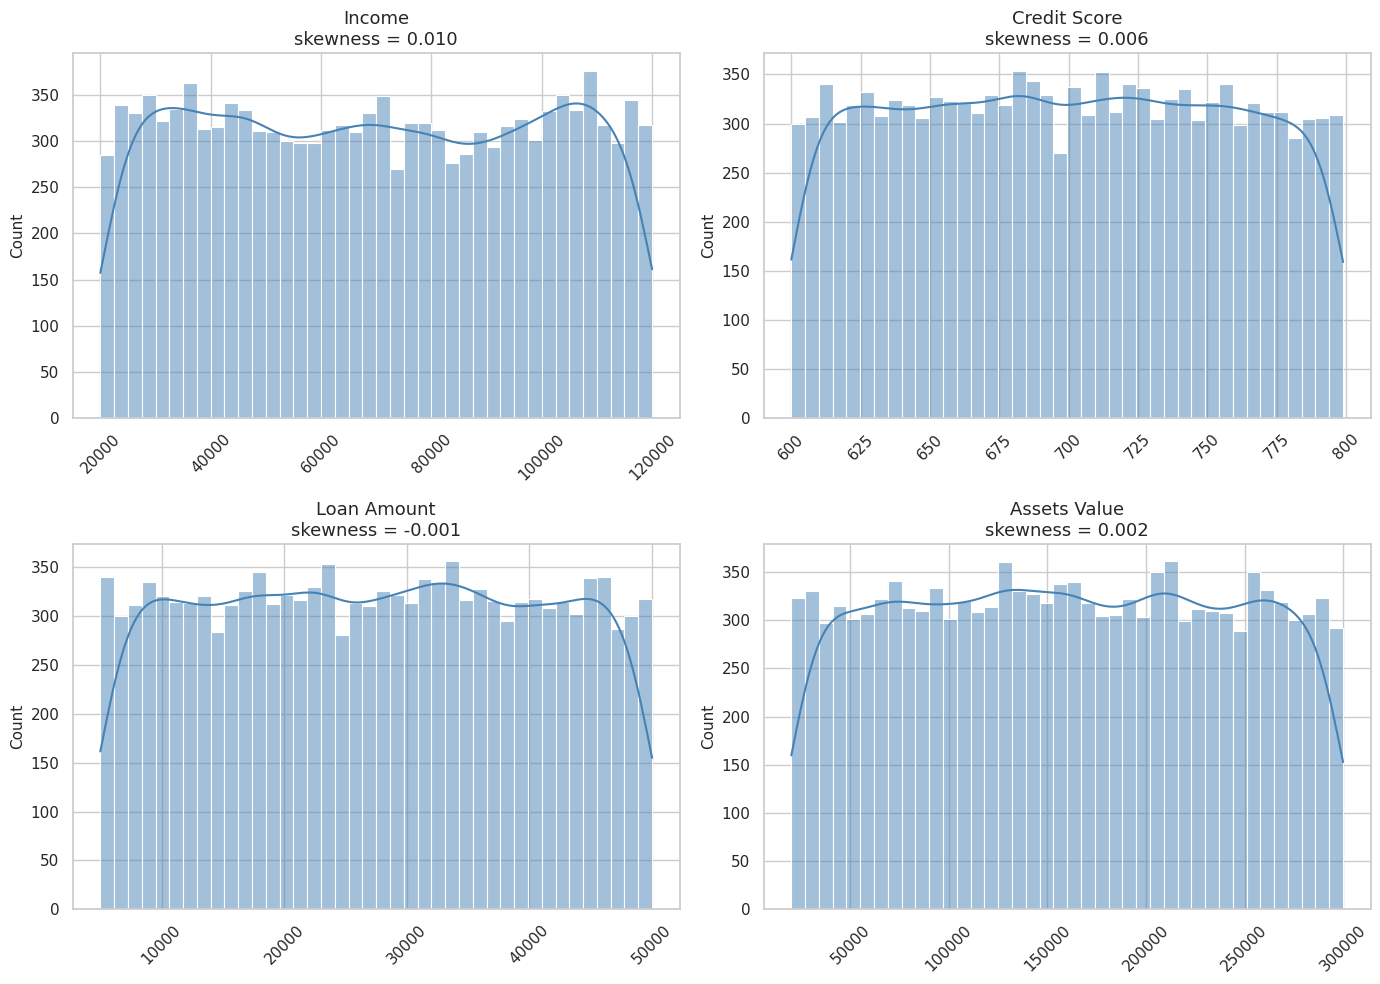

In [127]:
cols=["Income","Credit Score","Loan Amount","Assets Value"]
n_cols = len(cols)

fig, axes = plt.subplots(
    nrows=(n_cols + 1) // 2,
    ncols=2,
    figsize=(14, 5 * ((n_cols + 1) // 2))
)

axes = axes.flatten()
for ax, col in zip(axes, numeric_missing_cols):

    vals = df[col].dropna()

    sns.histplot(
        vals,
        bins=40,
        kde=True,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"{col}\nskewness = {skew(vals):.3f}")
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=45)

for i in range(len(numeric_missing_cols), len(axes)):
    fig.delaxes(axes[i])
plt.tight_layout()
plt.show()

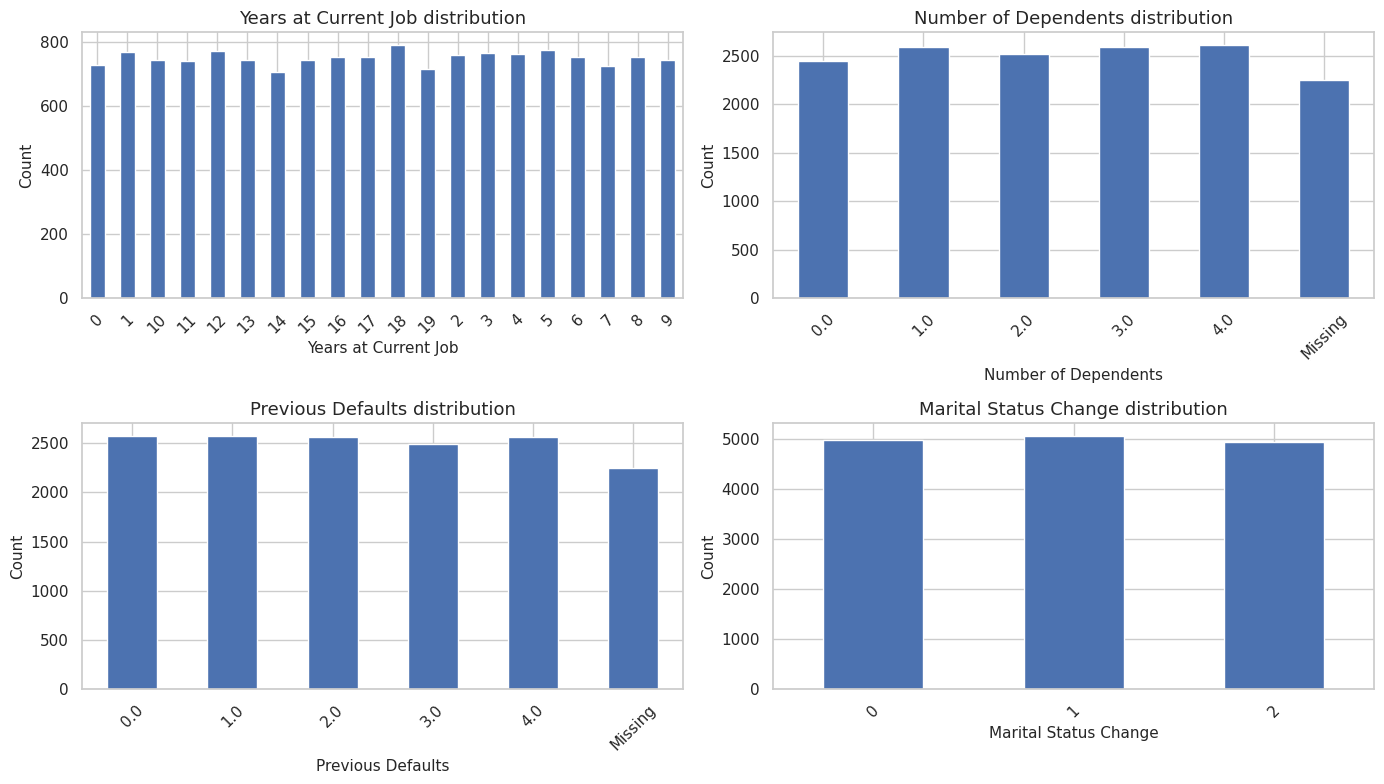

In [128]:
discrete_numeric = [
    "Years at Current Job",
    "Number of Dependents",
    "Previous Defaults",
    "Marital Status Change"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, col in zip(axes, discrete_numeric):
    counts = df[col].astype("string").fillna("Missing").value_counts().sort_index()
    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"{col} distribution")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

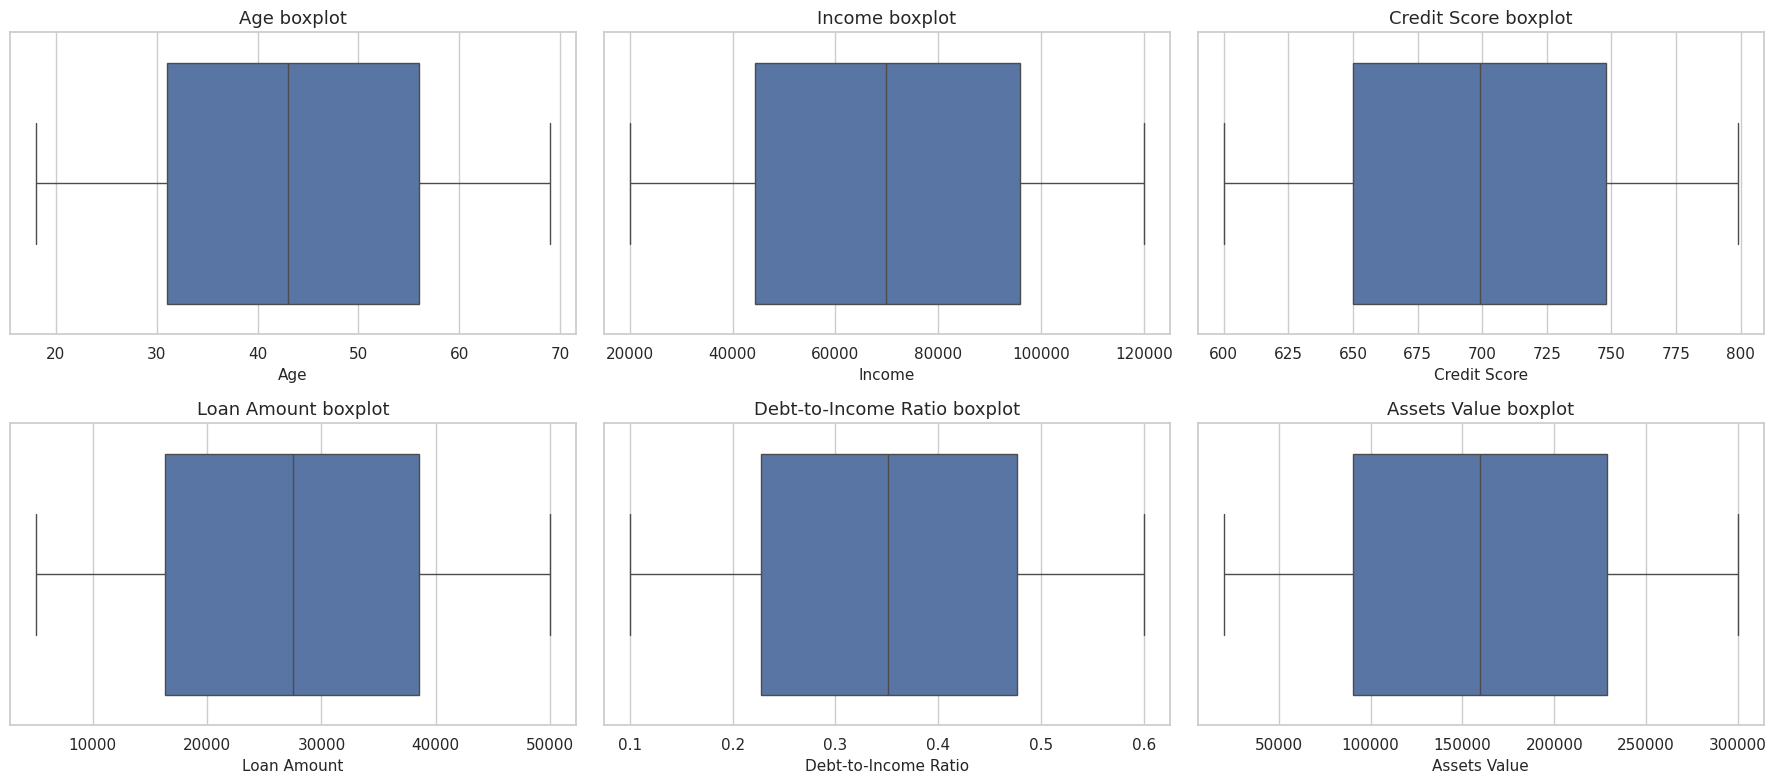

In [129]:
continuous_numeric = [
    "Age",
    "Income",
    "Credit Score",
    "Loan Amount",
    "Debt-to-Income Ratio",
    "Assets Value"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for ax, col in zip(axes, continuous_numeric):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"{col} boxplot")
    ax.set_xlabel(col)
    ax.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

In [132]:
cat_feature = "Country"
country_summary = pd.DataFrame({
    "count": df[cat_feature].value_counts(),
    "percentage": (df[cat_feature].value_counts(normalize=True) * 100).round(2)
})

country_summary.head(20)

,count,percentage
Country,,
Congo,124,0.8300
Korea,122,0.8100
French Guiana,87,0.5800
France,79,0.5300
Latvia,77,0.5100
Trinidad and Tobago,77,0.5100
Namibia,76,0.5100
Cote d'Ivoire,76,0.5100
Bulgaria,76,0.5100


In [134]:
country_counts = df["Country"].value_counts()

rare_country_summary = pd.DataFrame({
    "value": [
        df["Country"].nunique(),
        country_counts.max(),
        country_counts.min(),
        (country_counts == 1).sum(),
        (country_counts <= 5).sum(),
        (country_counts <= 10).sum(),
        (country_counts <= 50).sum(),
        (country_counts <= 100).sum(),

    ]
}, index=[
    "Total unique countries",
    "Largest country count",
    "Smallest country count",
    "Countries with 1 row",
    "Countries with 5 or fewer rows",
    "Countries with 10 or fewer rows",
    "Countries with 50 or fewer rows",
    "Countries with 100 or fewer rows"
])

rare_country_summary

,value
Total unique countries,243
Largest country count,124
Smallest country count,43
Countries with 1 row,0
Countries with 5 or fewer rows,0
Countries with 10 or fewer rows,0
Countries with 50 or fewer rows,17
Countries with 100 or fewer rows,241


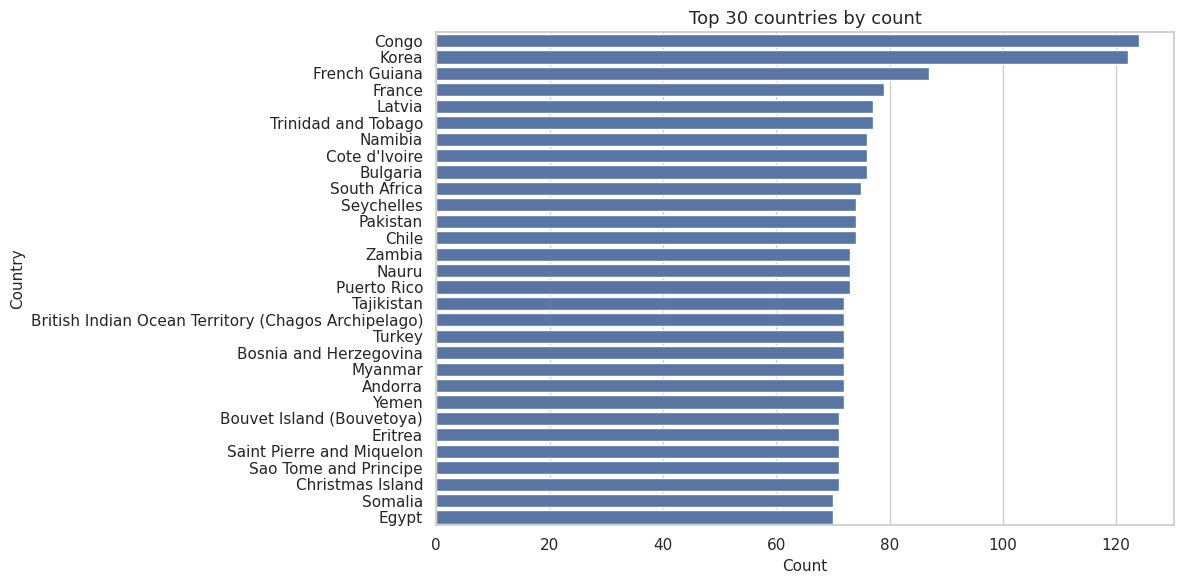

In [136]:
top_30_countries = country_summary.head(30)

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    x=top_30_countries["count"],
    y=top_30_countries.index,
    ax=ax
)

ax.set_title("Top 30 countries by count")
ax.set_xlabel("Count")
ax.set_ylabel("Country")

plt.tight_layout()
plt.show()


Gender


,count,percentage
Gender,,
Non-binary,5059,33.7300
Female,4990,33.2700
Male,4951,33.0100


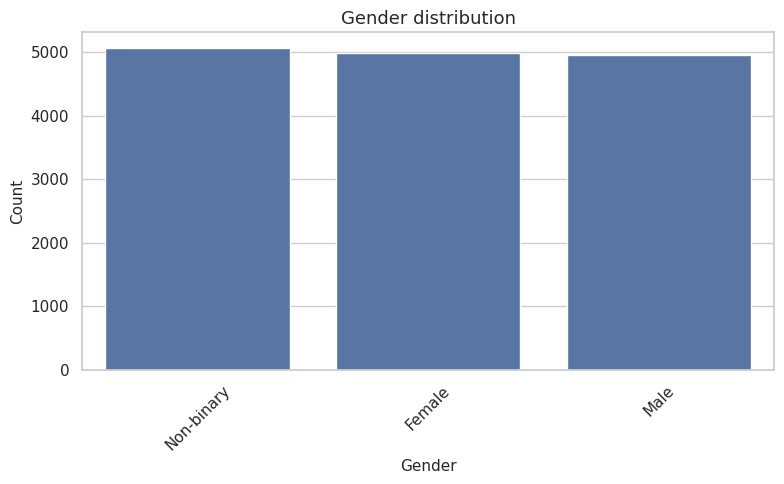


Education Level


,count,percentage
Education Level,,
Bachelor's,3829,25.5300
High School,3774,25.1600
PhD,3760,25.0700
Master's,3637,24.2500


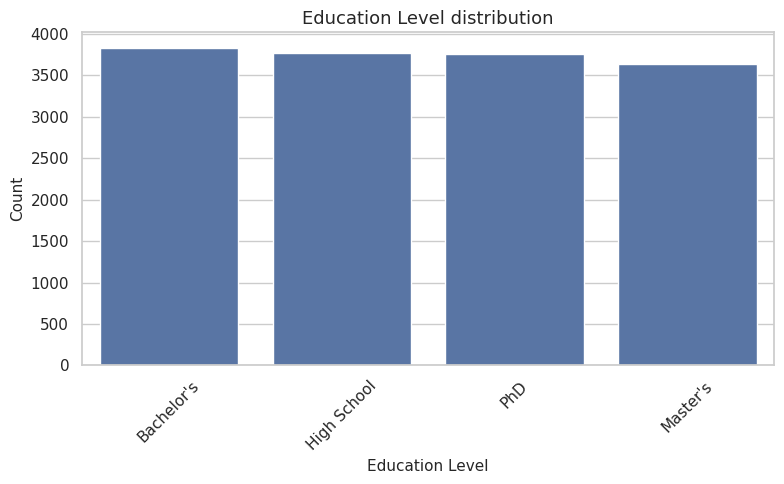


Marital Status


,count,percentage
Marital Status,,
Widowed,3893,25.9500
Divorced,3787,25.2500
Single,3697,24.6500
Married,3623,24.1500


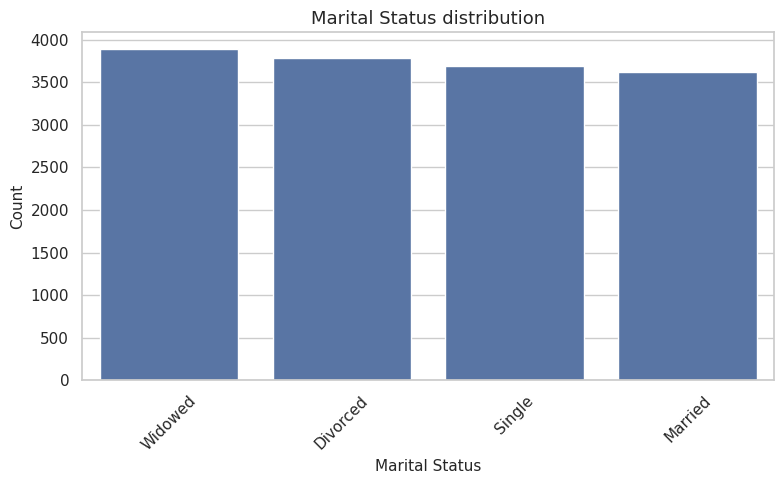


Loan Purpose


,count,percentage
Loan Purpose,,
Personal,3771,25.1400
Home,3766,25.1100
Business,3738,24.9200
Auto,3725,24.8300


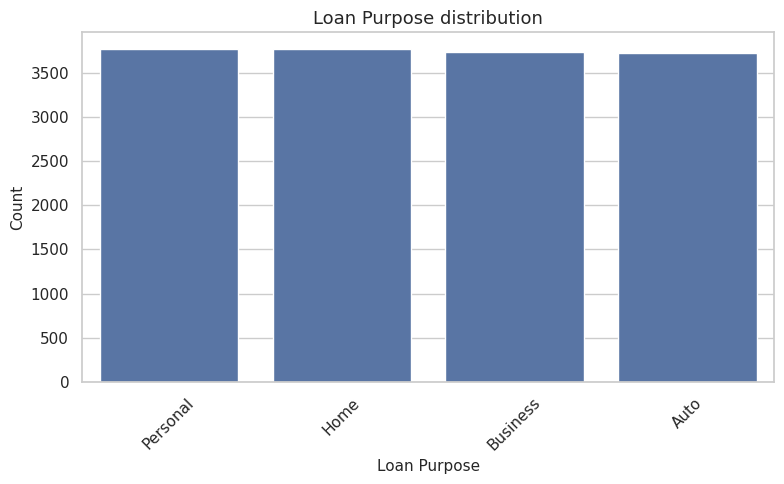


Employment Status


,count,percentage
Employment Status,,
Employed,5026,33.5100
Self-employed,4991,33.2700
Unemployed,4983,33.2200


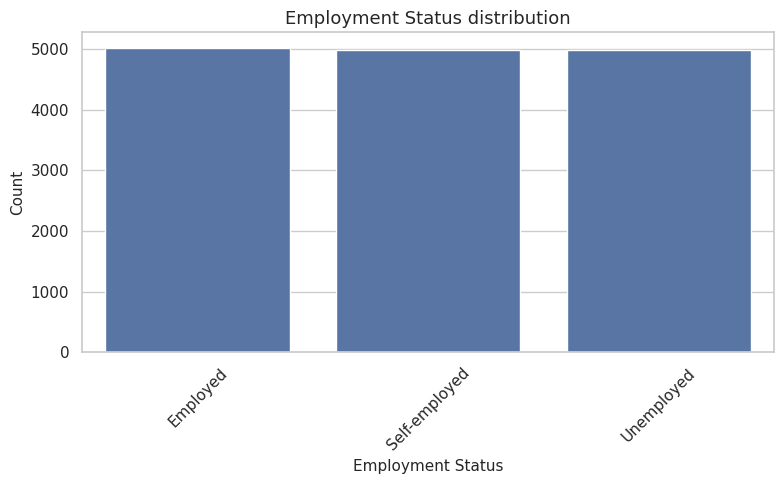


Payment History


,count,percentage
Payment History,,
Good,3822,25.4800
Excellent,3789,25.2600
Poor,3716,24.7700
Fair,3673,24.4900


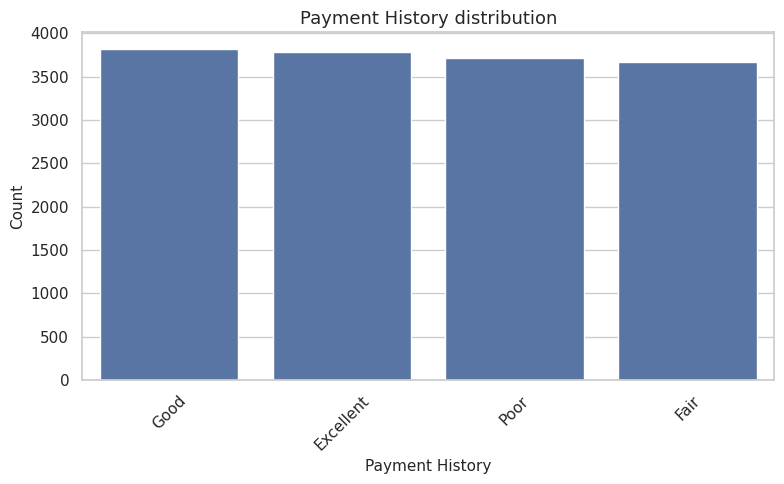

In [142]:
selected_categorical = [
    "Gender",
    "Education Level",
    "Marital Status",
    "Loan Purpose",
    "Employment Status",
    "Payment History",
]

for col in selected_categorical:
    summary = pd.DataFrame({
        "count": df[col].value_counts(),
        "percentage": (df[col].value_counts(normalize=True) * 100).round(2)
    })

    print(f"\n{col}")
    display(summary)

    fig, ax = plt.subplots(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        ax=ax
    )

    ax.set_title(f"{col} distribution")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()

In [148]:
scaling_features = [
    "Age",
    "Income",
    "Credit Score",
    "Loan Amount",
    "Debt-to-Income Ratio",
    "Assets Value",
    "Years at Current Job"
]

scaler = MinMaxScaler()

df_scaled = df.copy()
df_scaled[scaling_features] = scaler.fit_transform(df_scaled[scaling_features])

In [149]:
df_scaled

,Age,Gender,Education Level,Marital Status,Income,Credit Score,Loan Amount,Loan Purpose,Employment Status,Years at Current Job,Payment History,Debt-to-Income Ratio,Assets Value,Number of Dependents,City,State,Country,Previous Defaults,Marital Status Change,Risk Rating
0,0.6078,Male,PhD,Divorced,0.5280,0.4422,0.9048,Business,Unemployed,1.0000,Poor,0.1086,0.3578,0.0000,Port Elizabeth,AS,Cyprus,2.0000,2,Low
1,0.7647,Female,Bachelor's,Widowed,NaN,0.4523,0.6408,Auto,Employed,0.3158,Fair,0.0978,0.1279,0.0000,North Catherine,OH,Turkmenistan,3.0000,2,Medium
2,0.0588,Non-binary,Master's,Single,0.3568,0.0000,0.7028,Home,Employed,0.4211,Fair,0.5248,0.5738,3.0000,South Scott,OK,Luxembourg,3.0000,2,Medium
3,0.8039,Male,Bachelor's,Single,0.0650,0.1106,0.4787,Personal,Unemployed,0.1053,Excellent,0.7100,0.4903,3.0000,Robinhaven,PR,Uganda,4.0000,2,Medium
4,0.1373,Non-binary,Bachelor's,Widowed,0.2942,0.8342,0.7007,Personal,Unemployed,0.5263,Fair,0.0865,0.9541,NaN,New Heather,IL,Namibia,3.0000,1,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,0.0980,Non-binary,Bachelor's,Widowed,0.2809,0.0452,0.4708,Home,Self-employed,0.1053,Fair,0.4353,NaN,4.0000,Susanstad,TN,Djibouti,2.0000,0,Low
14996,0.7451,Male,PhD,Single,0.8719,0.5025,0.6692,Auto,Self-employed,0.5263,Fair,0.1103,0.2109,NaN,Port Heather,WA,Congo,0.0000,0,Medium
14997,0.2157,Non-binary,PhD,Married,0.2625,0.2111,0.8749,Home,Unemployed,1.0000,Excellent,0.9881,0.6318,4.0000,South Morganchester,LA,Palau,2.0000,1,High
14998,0.6863,Non-binary,PhD,Divorced,0.2018,0.1910,0.6167,Home,Self-employed,0.6316,Excellent,0.7561,0.9145,NaN,Port Wayne,AK,Rwanda,0.0000,2,High


Before comparing variables with each other, I first checked the features one by one. The goal was to see whether any numeric columns are strongly skewed, whether any categorical column is dominated by one category, and whether transformations or scaling are needed later.

### Numeric feature shape

The continuous financial columns do not show strong skewness. The skewness values are very close to `0`:

The histograms and boxplots support the same conclusion. The distributions look fairly even, and the boxplots do not show strong visible outliers. Because of this, I would not apply transformations such as `log1p`, square root, or Yeo-Johnson to these columns. A transformation would make the values harder to explain, but it would not improve the distribution much. For EDA, I would keep the original values because they are easy to understand. For example, `Income`, `Loan Amount`, and `Assets Value` are more meaningful in their original units. For modeling, I would focus more on scaling than transformation, because the issue is not skewness but different feature ranges.

### Scaling decision

Even though transformations are not needed, scaling can still be useful later in modeling. The numeric features are measured on very different scales. For example, `Debt-to-Income Ratio` is a small decimal value, `Credit Score` is around 600–799, while `Income`, `Loan Amount`, and `Assets Value` are much larger money-based values. Because the boxplots do not show strong outliers, `MinMaxScaler` would be a reasonable scaling choice. It would scale numeric features to the range `[0, 1]`, which is useful for models that are sensitive to feature size, such as KNN, SVM, neural networks, PCA, or regularized regression.

### Categorical balance: does one category dominate?

I checked the categorical features to see whether one category dominates or whether the categories are balanced enough for comparison.

For the lower-cardinality categorical features, the distributions are very balanced:

| Feature | Main finding |
|---|---|
| `Gender` | Balanced across `Non-binary`, `Female`, and `Male`, each around 33%. |
| `Education Level` | Balanced across the four education levels, each around 24–26%. |
| `Marital Status` | Balanced across the four categories, each around 24–26%. |
| `Loan Purpose` | Balanced across `Personal`, `Home`, `Business`, and `Auto`, each around 25%. |
| `Employment Status` | Balanced across `Employed`, `Self-employed`, and `Unemployed`, each around 33%. |
| `Payment History` | Balanced across `Good`, `Excellent`, `Poor`, and `Fair`, each around 24–25%. |

This means that for these features, no single category dominates the column. They are safe to compare in EDA because each category has enough rows.

`Country` is different. It has **243 unique countries**, so it is a high-cardinality categorical feature. The most common country is `Congo` with only **124 rows**, which is **0.83%** of the dataset. The next most common country is `Korea` with **122 rows**, or **0.81%** of the dataset. This means that no country dominates the feature.

At the same time, `Country` is not balanced in a simple way. There are many country categories, and most of them have relatively small counts. There are **241 countries with 100 or fewer rows**, and **17 countries with 50 or fewer rows**. So `Country` is not dominated by one category, but it is still difficult to use directly because it is spread across many small groups.

Because of that, I would be careful when using `Country` in presentations or modeling. Comparing financial risk by country may be unstable for countries with small sample sizes. For modeling, one-hot encoding `Country` would create many columns, so it may be better to group rare countries, use another encoding method, or decide whether the feature is useful enough to keep.

In [150]:
df_rel = df.copy()

risk_order = ["Low", "Medium", "High"]
risk_map = {
    "Low": 1,
    "Medium": 2,
    "High": 3
}

df_rel["RiskRating_num"] = df_rel["Risk Rating"].map(risk_map)

df_rel[["Risk Rating", "RiskRating_num"]].head()

,Risk Rating,RiskRating_num
0,Low,1
1,Medium,2
2,Medium,2
3,Medium,2
4,Low,1


In [159]:
numeric_features = [
    "Age",
    "Income",
    "Credit Score",
    "Loan Amount",
    "Debt-to-Income Ratio",
    "Assets Value",
    "Years at Current Job",
]

In [167]:
numeric_relationships = []

for col in numeric_features:
    tmp = df_rel[[col, "RiskRating_num"]].dropna()

    spearman_corr = tmp[col].corr(tmp["RiskRating_num"], method="spearman")
    pearson_corr = tmp[col].corr(tmp["RiskRating_num"], method="pearson")

    medians = df_rel.groupby("Risk Rating")[col].median().reindex(risk_order)

    numeric_relationships.append({
        "feature": col,
        "spearman": spearman_corr,
        "pearson": pearson_corr,
        "abs_diff": abs(spearman_corr - pearson_corr),
        "median_low": medians.loc["Low"],
        "median_medium": medians.loc["Medium"],
        "median_high": medians.loc["High"],
        "high_minus_low_median": medians.loc["High"] - medians.loc["Low"]
    })

numeric_relationships = (
    pd.DataFrame(numeric_relationships)
    .sort_values("spearman", key=abs, ascending=False)
)

numeric_relationships

,feature,spearman,pearson,abs_diff,median_low,median_medium,median_high,high_minus_low_median
6,Years at Current Job,0.0127,0.0129,0.0002,9.0000,10.0000,10.0000,1.0000
3,Loan Amount,0.0108,0.0124,0.0016,"27,362.0000","27,609.5000","28,129.0000",767.0000
1,Income,0.0091,0.0049,0.0042,"69,336.0000","71,586.0000","66,662.5000","-2,673.5000"
0,Age,-0.0061,-0.0040,0.0021,43.0000,43.0000,43.0000,0.0000
2,Credit Score,0.0038,0.0042,0.0005,700.0000,699.0000,698.5000,-1.5000
4,Debt-to-Income Ratio,0.0037,0.0035,0.0002,0.3497,0.3512,0.3549,0.0052
5,Assets Value,0.0033,0.0046,0.0013,"159,513.0000","158,141.0000","160,753.5000","1,240.5000"


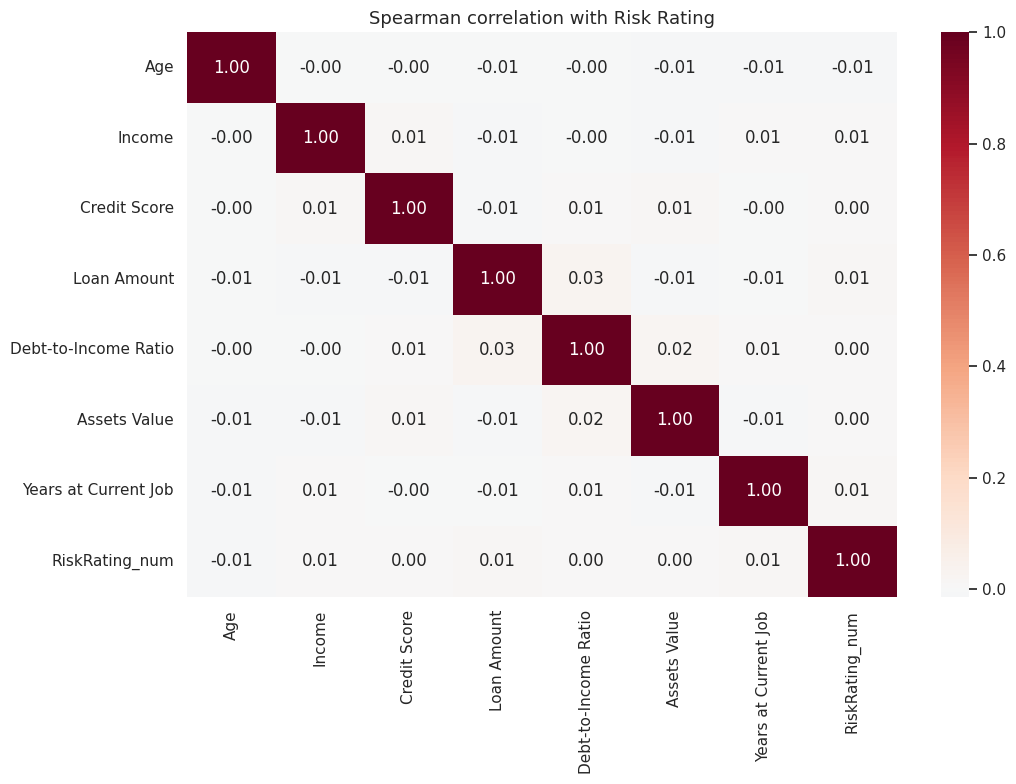

In [161]:
numeric_for_corr = numeric_features + ["RiskRating_num"]

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    df_rel[numeric_for_corr].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    ax=ax
)

ax.set_title("Spearman correlation with Risk Rating")
plt.tight_layout()
plt.show()

In [168]:
discrete_count_features = [
    "Number of Dependents",
    "Previous Defaults"
]


Number of Dependents - percentages


Risk Rating,Low,Medium,High
Number of Dependents,,,
0,60.7000,29.2300,10.0700
1,59.5400,29.8100,10.6600
2,60.4900,29.9700,9.5400
3,60.3200,30.1400,9.5400
4,59.4000,30.6500,9.9500
Missing,59.5600,30.1800,10.2700


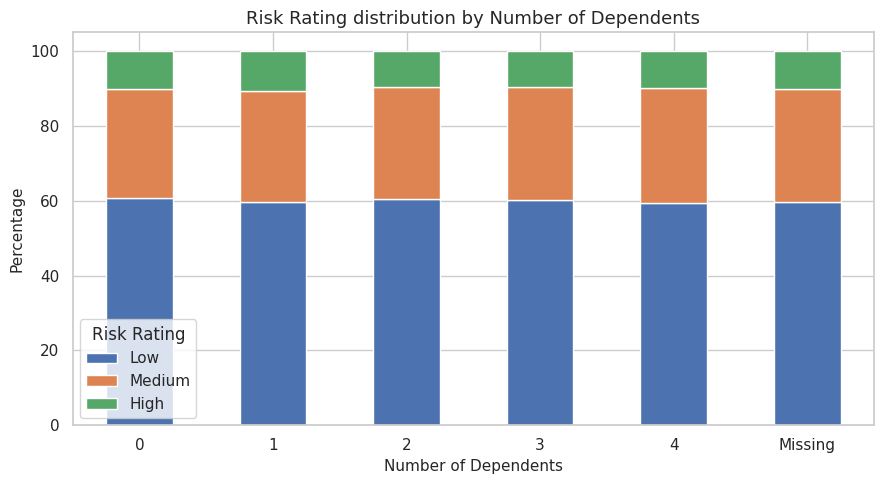


Previous Defaults - percentages


Risk Rating,Low,Medium,High
Previous Defaults,,,
0,62.3500,28.1200,9.5300
1,58.1200,30.7900,11.0900
2,59.9100,29.8900,10.2000
3,59.5500,30.0400,10.4100
4,60.9600,29.5200,9.5200
Missing,58.9800,31.8700,9.1600


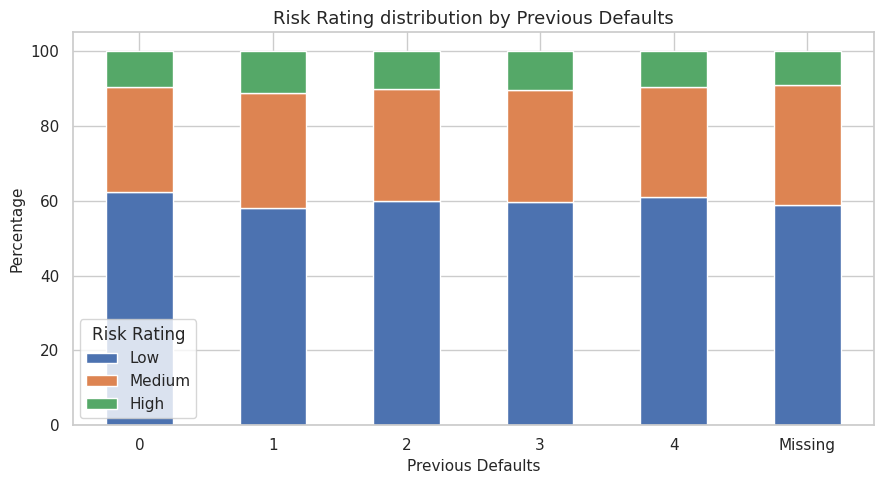

In [171]:
for col in discrete_count_features:
    tmp = df_rel[[col, "Risk Rating"]].copy()

    tmp[col] = tmp[col].astype("Int64").astype("string").fillna("Missing")
    
    percent_table = pd.crosstab(
        tmp[col],
        tmp["Risk Rating"],
        normalize="index"
    )[risk_order] * 100

  

    print(f"\n{col} - percentages")
    display(percent_table.round(2))

    ax = percent_table.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5)
    )

    ax.set_title(f"Risk Rating distribution by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Percentage")
    ax.legend(title="Risk Rating")
    ax.tick_params(axis="x", rotation=0)

    plt.tight_layout()
    plt.show()

In [162]:
def cramers_v(x, y):
    contingency = pd.crosstab(x, y)

    chi2 = stats.chi2_contingency(contingency)[0]
    n = contingency.values.sum()

    r, k = contingency.shape

    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    return np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1))

In [173]:
discrete_cramers_scores = pd.Series({
    col: cramers_v(
        df_rel[col].astype("Int64").astype("string").fillna("Missing"),
        df_rel["Risk Rating"]
    )
    for col in discrete_count_features
}).sort_values(ascending=False)
discrete_cramers_scores

Previous Defaults      0.0158
Number of Dependents   0.0000
dtype: float64

In [163]:
categorical_features = [
    "Gender",
    "Education Level",
    "Marital Status",
    "Loan Purpose",
    "Employment Status",
    "Payment History",
    "Marital Status Change"
]

In [164]:
cramers_scores = pd.Series(
    {
        col: cramers_v(df_rel[col], df_rel["Risk Rating"])
        for col in categorical_features
    }
).sort_values(ascending=False)

cramers_scores

Marital Status Change   0.0175
Gender                  0.0111
Loan Purpose            0.0090
Employment Status       0.0059
Education Level         0.0000
Marital Status          0.0000
Payment History         0.0000
dtype: float64

Risk Rating,Low,Medium,High
Gender,,,
Female,59.7400,29.8800,10.3800
Male,59.0000,30.6000,10.4000
Non-binary,61.2400,29.5300,9.2300


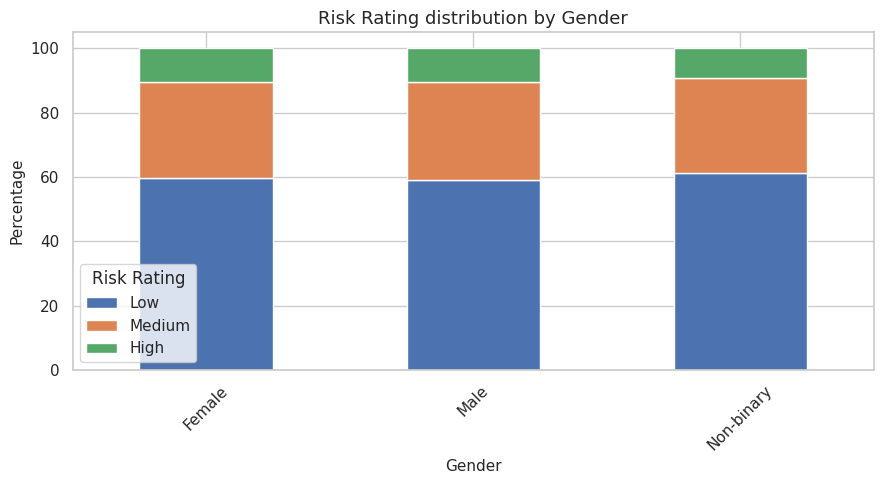

Risk Rating,Low,Medium,High
Education Level,,,
Bachelor's,60.2800,30.0900,9.6400
High School,59.5100,30.3900,10.1000
Master's,60.8500,29.2800,9.8700
PhD,59.3900,30.2100,10.4000


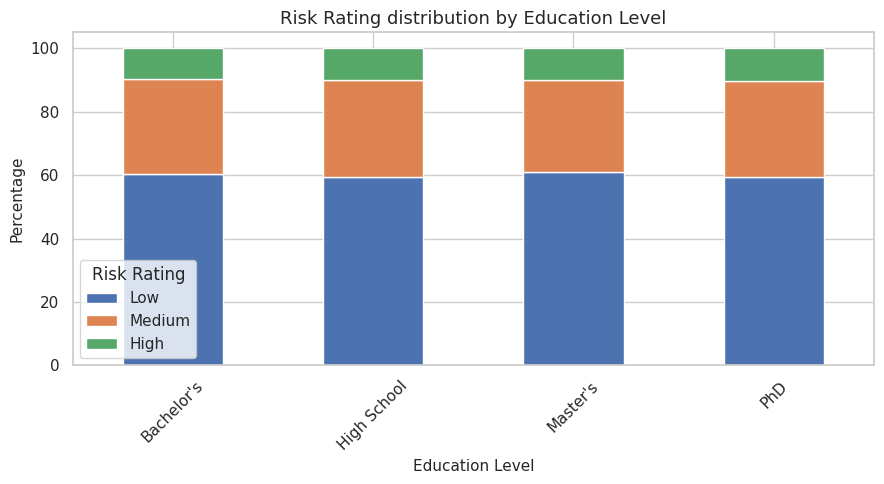

Risk Rating,Low,Medium,High
Marital Status,,,
Divorced,60.0700,30.0500,9.8800
Married,60.9400,29.8600,9.1900
Single,59.9900,29.7500,10.2500
Widowed,59.0500,30.3100,10.6300


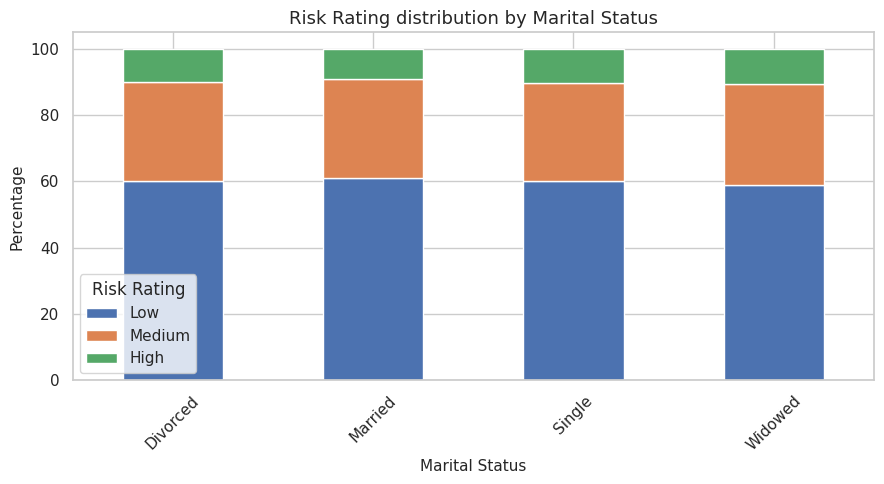

Risk Rating,Low,Medium,High
Loan Purpose,,,
Auto,59.1700,30.1200,10.7100
Business,60.5900,30.4400,8.9600
Home,59.8800,30.2200,9.9000
Personal,60.3600,29.2200,10.4200


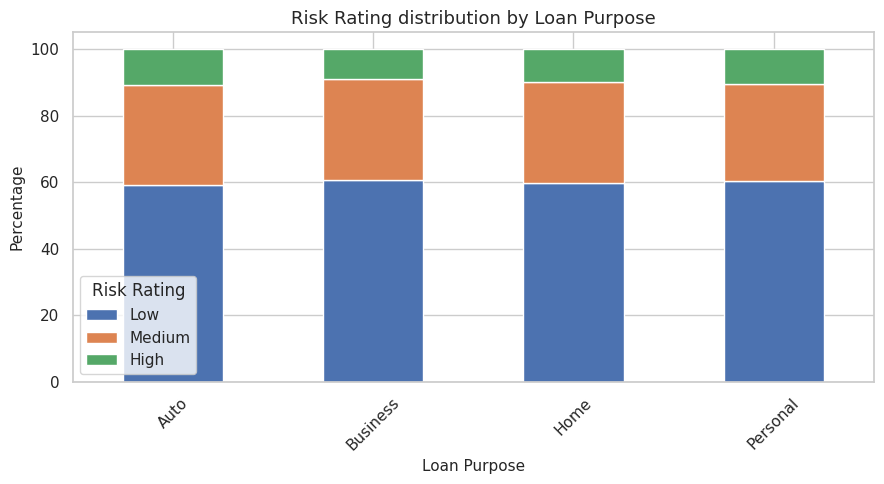

Risk Rating,Low,Medium,High
Employment Status,,,
Employed,58.9700,30.7400,10.2900
Self-employed,60.5100,29.2700,10.2200
Unemployed,60.5300,29.9800,9.4900


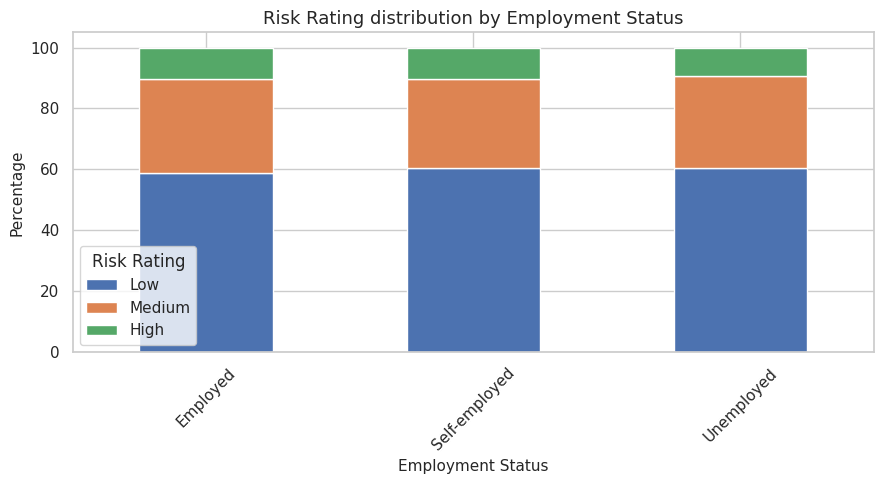

Risk Rating,Low,Medium,High
Payment History,,,
Excellent,61.3600,29.3700,9.2600
Fair,59.4900,30.3600,10.1600
Good,59.3400,30.3000,10.3600
Poor,59.8000,29.9800,10.2300


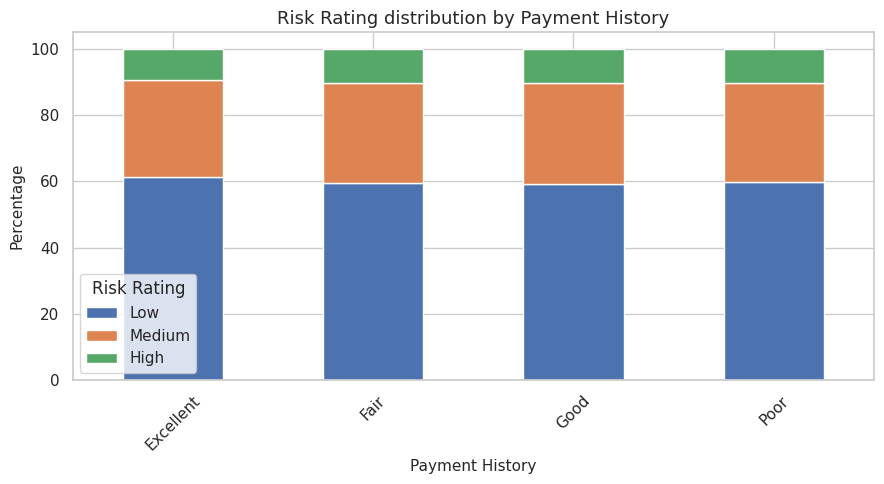

Risk Rating,Low,Medium,High
Marital Status Change,,,
0,60.0000,30.7800,9.2200
1,60.5700,29.8400,9.5900
2,59.4100,29.3800,11.2000


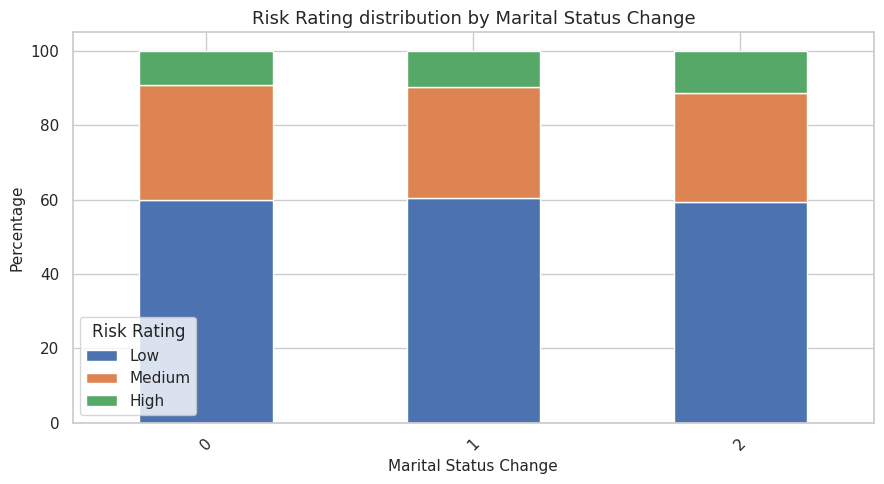

In [166]:

for col in categorical_features:
    percentage_table = pd.crosstab(
        df_rel[col],
        df_rel["Risk Rating"],
        normalize="index"
    )[risk_order] * 100

    display(percentage_table.round(2))

    ax = percentage_table.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5)
    )

    ax.set_title(f"Risk Rating distribution by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Percentage")
    ax.legend(title="Risk Rating")
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()

## Relationship analysis with `Risk Rating`

In this part, I checked if the main features have a clear connection with `Risk Rating`. Since the target has three ordered values, `Low`, `Medium`, and `High`, I used a numeric version of it to compare it with numeric features. For categorical features, I used Cramér’s V to check how strongly they are connected with the target.

The numeric features do not show a strong relationship with `Risk Rating`. Features like `Income`, `Credit Score`, `Loan Amount`, `Assets Value`, `Debt-to-Income Ratio`, `Age`, and `Years at Current Job` all have correlations very close to zero. This means they do not clearly separate Low, Medium, and High risk clients. For example, the median credit score is almost the same across all three risk groups.

The count-like features also do not show a strong pattern. `Number of Dependents` has almost no relationship with `Risk Rating`, and `Previous Defaults` also shows only a very weak connection. This is a little surprising because, in real financial data, previous defaults would usually be expected to have a stronger relationship with financial risk.

The categorical features show the same result. Features like `Gender`, `Education Level`, `Marital Status`, `Loan Purpose`, `Employment Status`, `Payment History`, and `Marital Status Change` all have very low Cramér’s V values. The risk distribution inside most categories is almost the same as the full dataset: around 60% Low risk, 30% Medium risk, and 10% High risk.

The main thing is that `Risk Rating` is spread almost the same way across most features. There is no strong single feature that clearly explains the target. This may mean that the dataset is synthetic, that the target was created with weak connection to the visible features, or that the useful information is hidden in combinations of features instead of one feature alone.

It would be better to try models that can capture interactions between features, such as tree-based models, and evaluate them with metrics like precision, recall, F1-score, and a confusion matrix.

Two domain questions from this dataset are if `Payment History` and `Previous Defaults` affect `Risk Rating`.

From the results, `Payment History` does not show a meaningful relationship with `Risk Rating`. This is surprising because, in real financial data, people with poor payment history are usually expected to have higher risk. However, in this dataset, the risk percentages are almost the same for `Excellent`, `Good`, `Fair`, and `Poor`, and Cramér’s V is `0.0000`.

`Previous Defaults` also shows only a very weak relationship with `Risk Rating`. Even though previous defaults should normally be connected to higher risk, the Cramér’s V value is only `0.0158`. The High-risk percentage changes only slightly between default groups, so previous defaults do not clearly separate Low, Medium, and High risk clients in this dataset.

In [175]:
def iqr_outliers(s, k=1.5):
    """Return True where s is outside [Q1 - k*IQR, Q3 + k*IQR]."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def zscore_outliers(s, threshold=3):
    """Classic z-score method."""
    z = (s - s.mean()) / s.std()
    return z.abs() > threshold

def modified_zscore_outliers(s, threshold=3.5):
    """Robust z-score using median and MAD."""
    median = s.median()
    mad = (s - median).abs().median()
    if mad == 0:
        return pd.Series(False, index=s.index)
    z = 0.6745 * (s - median) / mad
    return z.abs() > threshold

In [176]:
domain_checks = pd.Series({
    "Age < 18": (df["Age"] < 18).sum(),
    "Age > 100": (df["Age"] > 100).sum(),
    "Income <= 0": (df["Income"] <= 0).sum(),
    "Credit Score < 300": (df["Credit Score"] < 300).sum(),
    "Credit Score > 850": (df["Credit Score"] > 850).sum(),
    "Loan Amount <= 0": (df["Loan Amount"] <= 0).sum(),
    "Debt-to-Income Ratio < 0": (df["Debt-to-Income Ratio"] < 0).sum(),
    "Debt-to-Income Ratio > 1": (df["Debt-to-Income Ratio"] > 1).sum(),
    "Assets Value < 0": (df["Assets Value"] < 0).sum(),
    "Years at Current Job < 0": (df["Years at Current Job"] < 0).sum(),
    "Years at Current Job > Age": (df["Years at Current Job"] > df["Age"]).sum(),
    "Number of Dependents < 0": (df["Number of Dependents"] < 0).sum(),
    "Previous Defaults < 0": (df["Previous Defaults"] < 0).sum()
})

domain_checks.to_frame("n_rows")

,n_rows
Age < 18,0
Age > 100,0
Income <= 0,0
Credit Score < 300,0
Credit Score > 850,0
Loan Amount <= 0,0
Debt-to-Income Ratio < 0,0
Debt-to-Income Ratio > 1,0
Assets Value < 0,0
Years at Current Job < 0,0


In [179]:
job_age_issue_rows = df[
    df["Years at Current Job"] > df["Age"]
][
    [
        "Age",
        "Years at Current Job",
        "Employment Status",
        "Income",
        "Credit Score",
        "Loan Amount",
        "Risk Rating"
    ]
]

job_age_issue_rows

,Age,Years at Current Job,Employment Status,Income,Credit Score,Loan Amount,Risk Rating
3252,18,19,Employed,NaN,672.0000,"14,953.0000",Medium
3600,18,19,Self-employed,"111,650.0000",658.0000,"5,131.0000",Medium
3969,18,19,Self-employed,"96,757.0000",757.0000,"17,869.0000",Low
5363,18,19,Self-employed,"54,638.0000",720.0000,"45,176.0000",High
9235,18,19,Self-employed,"93,131.0000",623.0000,"46,354.0000",High
9292,18,19,Unemployed,"24,441.0000",720.0000,NaN,Low
11677,18,19,Unemployed,"70,637.0000",726.0000,"6,049.0000",Low
11765,18,19,Unemployed,"112,781.0000",704.0000,"14,142.0000",Medium
12508,18,19,Self-employed,"31,025.0000",605.0000,"29,449.0000",Low
12706,18,19,Unemployed,"76,147.0000",NaN,"32,339.0000",Low


In [177]:
outlier_numeric_features = [
    "Age",
    "Income",
    "Credit Score",
    "Loan Amount",
    "Debt-to-Income Ratio",
    "Assets Value",
    "Years at Current Job"
]

In [178]:
outlier_method_summary = []

for col in outlier_numeric_features:
    outlier_method_summary.append({
        "feature": col,
        "IQR_1.5x": iqr_outliers(df[col], 1.5).sum(),
        "IQR_3x": iqr_outliers(df[col], 3.0).sum(),
        "Z_score_3": zscore_outliers(df[col], 3).sum(),
        "Modified_Z_3.5": modified_zscore_outliers(df[col], 3.5).sum()
    })

outlier_method_summary = pd.DataFrame(outlier_method_summary)

outlier_method_summary

,feature,IQR_1.5x,IQR_3x,Z_score_3,Modified_Z_3.5
0,Age,0,0,0,0
1,Income,0,0,0,0
2,Credit Score,0,0,0,0
3,Loan Amount,0,0,0,0
4,Debt-to-Income Ratio,0,0,0,0
5,Assets Value,0,0,0,0
6,Years at Current Job,0,0,0,0


### Outlier and data quality summary

I checked the main numeric columns using IQR, Z-score, and modified Z-score. None of these methods found statistical outliers, so the numeric values look controlled and there are no extreme values based on these checks.

I also checked basic domain rules. Most values were valid, such as no negative income, no invalid credit scores, no negative loan amounts, and no invalid debt-to-income ratios. The only issue found was with `Years at Current Job`. There are **11 rows** where the person is `18` years old but has `19` years at the current job, which is not realistic. This is not a statistical outlier, but a logical data quality issue.

I would not drop these rows immediately because the other information may still be useful. A better option is to investigate them or cap `Years at Current Job` to a realistic value.

## 6 · Final Conclusion

After spending time exploring this financial risk dataset, my main conclusion is that it is useful for practicing data analysis, but I would **not use it for serious model training in its current form**. The data contains missing values, unclear columns, some unrealistic records, and most importantly, the features do not show clear relationships with the target variable `Risk Rating`.


## Main findings from the analysis

### 1. The risk label does not match the financial features very clearly

The most important finding is that the target variable, `Risk Rating`, is not strongly connected to the main financial features. I expected people with lower credit scores, poor payment history, or more previous defaults to have noticeably higher risk ratings. However, the analysis showed that these patterns are very weak or almost absent. For example, `Payment History` had almost no relationship with `Risk Rating`, and `Previous Defaults` showed only a very small difference between the risk groups. This was surprising because these features would normally be important in a real financial risk setting.

---

### 2. Some columns raise clear data quality concerns

A few parts of the dataset look unreliable or unclear. `Marital Status Change` is coded as `0`, `1`, and `2`, but the dataset does not explain what those codes mean. `Previous Defaults` is understandable in general, but its exact meaning is not fully defined. The location columns also need caution. `City` is especially problematic because nearly every city appears only once, which makes it difficult to use in any meaningful way. I would remove `City` from later modeling because it is unlikely to help and would create unnecessary complexity.

The clearest data quality error is the set of **11 rows where the person is 18 years old but has 19 years at their current job**. These values are unrealistic when the two columns are compared.

---

## Final recommendation

I would **not recommend using this dataset for serious financial risk model training in its current form**. The main reasons are:

- the target `Risk Rating` is imbalanced,
- expected financial patterns are very weak, we have some percentage of rows that are classifed as low risk for Employed and Unemployed type of category which doesnt make sense
- some columns are unclear
- and a small number of rows contain impossible values.